# 12. Fallacy vs. valid argument detection

The proposal planned to detect fallacies "alongside valid arguments". The main dataset has
no valid arguments, so this was impossible until the external data arrived. Two sources
contain **both** classes:

* **contrastive**: 703 pairs generated with an LLM (Kaggle, navy007; Singh, 2026). Each valid argument has a fallacious twin that
  keeps the same topic and most of the wording ("…because she missed three deadlines" vs
  "…because she dresses unprofessionally"). A model that relies on topic words cannot
  separate a pair; only the reasoning words differ.
* **comments**: CoCoLoFa news comments written by crowd workers (`cocolofa`) and Touché 2026
  Reddit comments (`touche`), each labelled "No Fallacy" or one of 8 fallacies.

Using only sources that contain both classes means a source's writing style cannot predict
the label. Short textbook examples (edu) and the main dataset are all-fallacy and are left
out for that reason.

**Protocol (declared in `src/config.py` before modelling).** Deterministic 70/15/15 split by
a hash of a *group* id: the contrastive pair (both twins always land in the same split; a
sentence shared by two pairs joins them into one group), or the near-duplicate cluster for
comments (cosine ≥ 0.8). Hyperparameters are chosen on **val**; **test** is used once,
in section 12.5.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             precision_score, recall_score)
from src.config import RESULTS, FIGURES, SEED
from src.data import load_dataset, get_splits
from src.features import word_tfidf
from src.models import linear_svm
from src.text import token_group
from src.external import binary_dataset

df, LABELS = load_dataset()
S = get_splits(df, LABELS); X_tr, Y_tr, _ = S["train"]
sel = json.loads((RESULTS / "selection.json").read_text())
cw = lambda s: None if s in (None, "None") else "balanced"
D = binary_dataset()
pd.crosstab([D.source, D.split], D.is_fallacy.map({0: "valid", 1: "fallacy"}), margins=True)

is_fallacy         fallacy  valid   All
source      split                      
cocolofa    test        19     17    36
            train       94     67   161
            val         27     13    40
contrastive test        93     93   186
            train      487    487   974
            val        123    123   246
touche      test        77     71   148
            train      321    337   658
            val         67     65   132
All                   1308   1273  2581

## 12.1 Zero-shot: does the main-dataset model flag valid arguments?
The linear SVM selected on the main dataset was trained only on fallacious text. We apply it,
unchanged, to every argument in this data (none of it was ever used for training) and treat
"predicts at least one of the 16 fallacies" as "fallacy". For a threshold-free view we also
score each argument by the calibrated SVM's highest label probability.

In [2]:
vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr)
s = sel["LinearSVM"]
svm = linear_svm(s["C"], cw(s["class_weight"])).fit(A, Y_tr)
cal = OneVsRestClassifier(CalibratedClassifierCV(LinearSVC(C=s["C"], class_weight=cw(s["class_weight"]), max_iter=20000),
                                                 method="sigmoid", cv=5)).fit(A, Y_tr)
Xb = vec.transform(D.argument)
D["zs_flag"] = (svm.predict(Xb).sum(1) > 0).astype(int)
D["zs_score"] = cal.predict_proba(Xb).max(1)

def zero_shot(g):
    v, f = g[g.is_fallacy == 0], g[g.is_fallacy == 1]
    return pd.Series({"n": len(g), "valid flagged as fallacy (FPR)": v.zs_flag.mean(),
                      "fallacies flagged (recall)": f.zs_flag.mean(), "accuracy": (g.zs_flag == g.is_fallacy).mean(),
                      "AUC of max probability": roc_auc_score(g.is_fallacy, g.zs_score)})
zs = D.groupby("source").apply(zero_shot); zs.loc["all"] = zero_shot(D); zs.round(3)

,n,valid flagged as fallacy (FPR),fallacies flagged (recall),accuracy,AUC of max probability
source,,,,,
cocolofa,237.0,0.474,0.571,0.553,0.529
contrastive,1406.0,0.380,0.634,0.627,0.664
touche,938.0,0.526,0.490,0.482,0.480
all,2581.0,0.441,0.576,0.568,0.599


In [3]:
C = D[D.source == "contrastive"].dropna(subset=["pair"])
pairs = C.pivot_table(index="pair", columns="is_fallacy", values="zs_score", aggfunc="first").dropna()
zs_pair = float((pairs[1] > pairs[0]).mean())
print(f"Contrastive pairs where the fallacious twin gets the higher score: {zs_pair:.1%} of {len(pairs)} (chance = 50%)")

Contrastive pairs where the fallacious twin gets the higher score: 68.0% of 703 (chance = 50%)


A model that has only ever seen fallacies flags a large share of valid arguments (the
"valid flagged" column) and misses many fallacies, so its accuracy is near chance on the comment sources
(0.48 to 0.55), whose classes its score barely separates (AUC 0.48 to 0.53). It ranks the
fallacious twin of a contrastive pair higher more often than chance, but far from reliably:
it has learned "this looks like an argument about X" more than "this argument reasons badly".

## 12.2 Trained binary detectors: candidates and baselines
All vectorisers are fitted on this task's **train** split.

* Majority class (predict the most frequent train label).
* Unigram BoW + logistic regression (C = 1), the analogue of the team's notebook-03 baseline.
* TF-IDF uni+bi + logistic regression (L2), C ∈ {0.1, 1, 10, 100}.
* TF-IDF uni+bi + linear SVM, C ∈ {0.01, 0.1, 1, 10}.

Selection: highest validation macro-F1 (classes are near-balanced, so this is close to accuracy).

In [4]:
tr, va, te = (D[D.split == k].reset_index(drop=True) for k in ["train", "val", "test"])
ytr, yva, yte = tr.is_fallacy.values, va.is_fallacy.values, te.is_fallacy.values
majority = int(ytr.mean() >= 0.5)

def fit(kind, C, train=tr):
    if kind == "BoW + LR":
        v = CountVectorizer(min_df=2, max_df=0.95); m = LogisticRegression(C=C, max_iter=3000)
    elif kind == "TF-IDF + LR":
        v = word_tfidf(ngram_range=(1, 2)); m = LogisticRegression(C=C, max_iter=3000)
    else:
        v = word_tfidf(ngram_range=(1, 2)); m = LinearSVC(C=C, max_iter=20000)
    m.fit(v.fit_transform(train.argument), train.is_fallacy.values)
    return v, m

def score_of(v, m, X):
    Z = v.transform(X)
    return m.decision_function(Z)

grid = [("BoW + LR", 1.0)] + [("TF-IDF + LR", c) for c in [0.1, 1, 10, 100]] + [("TF-IDF + linear SVM", c) for c in [0.01, 0.1, 1, 10]]
vrows = [{"model": "Majority class", "C": None, "val_macro_f1": f1_score(yva, np.full_like(yva, majority), average="macro"),
          "val_accuracy": accuracy_score(yva, np.full_like(yva, majority))}]
for kind, c in grid:
    v, m = fit(kind, c); p = m.predict(v.transform(va.argument))
    vrows.append({"model": kind, "C": c, "val_macro_f1": f1_score(yva, p, average="macro"), "val_accuracy": accuracy_score(yva, p)})
vgrid = pd.DataFrame(vrows); vgrid.to_csv(RESULTS / "binary_val_grid.csv", index=False); vgrid.round(4)

,model,C,val_macro_f1,val_accuracy
0,Majority class,NaN,0.3417,0.5191
1,BoW + LR,1.00,0.7243,0.7249
2,TF-IDF + LR,0.10,0.7250,0.7273
3,TF-IDF + LR,1.00,0.7505,0.7512
4,TF-IDF + LR,10.00,0.7601,0.7608
5,TF-IDF + LR,100.00,0.7482,0.7488
6,TF-IDF + linear SVM,0.01,0.7174,0.7201
7,TF-IDF + linear SVM,0.10,0.7456,0.7464
8,TF-IDF + linear SVM,1.00,0.7650,0.7656
9,TF-IDF + linear SVM,10.00,0.7290,0.7297


In [5]:
best = vgrid[vgrid.model.str.startswith("TF-IDF")].sort_values(["val_macro_f1", "C"], ascending=[False, True]).iloc[0]
sel["binary"] = {"model": best.model, "C": float(best.C), "val_macro_f1": float(best.val_macro_f1),
                 "selected_by": "validation macro-F1 (notebook 12), before the test split was scored"}
(RESULTS / "selection.json").write_text(json.dumps(sel, indent=2, default=float))
print("selected:", sel["binary"])

selected: {'model': 'TF-IDF + linear SVM', 'C': 1.0, 'val_macro_f1': 0.7650122759918313, 'selected_by': 'validation macro-F1 (notebook 12), before the test split was scored'}


## 12.3 What does the selected detector rely on?
Largest positive (→ fallacy) and negative (→ valid) weights of the selected model, refitted on
train, with the token groups of notebook 06.

In [6]:
v_b, m_b = fit(best.model, best.C)
w = np.ravel(m_b.coef_); vocab = v_b.get_feature_names_out()
top = lambda idx: [f"{vocab[i]} ({token_group(vocab[i])[0]})" for i in idx]
pd.DataFrame({"→ fallacy": top(np.argsort(-w)[:20]), "→ valid": top(np.argsort(w)[:20])})

,→ fallacy,→ valid
0,so (c),so we (c)
1,so the (c),cannot (f)
2,famous (c),has never (c)
3,the famous (c),data (t)
4,she is (f),lacks (t)
5,because it's (t),using (t)
6,will (f),we must (c)
7,you (f),argument (t)
8,my (f),is either (c)
9,would (f),engineer (t)


(t) topic, (c) cue, (f) function word. Two kinds of weight appear:

* **Genuine reasoning cues.** "so", "so the", "therefore the", "we either" push towards
  *fallacy* (a bare inference or a forced choice); "has never", "lacks", "data" push towards
  *valid* (a specific, checkable reason).
* **Artefacts of how the data was written.** The contrastive authority pairs swap an expert
  for a celebrity, so "famous", "celebrity", "chef" push towards *fallacy* and "engineer",
  "scientist" towards *valid*. That is the same shortcut problem as in notebook 06, on a
  smaller scale: the pairs remove topic words as a shortcut, but their construction pattern
  becomes a new one. ("gt" is the HTML entity `&gt;` used for quotes in the Touché Reddit comments.)

## 12.4 Cross-source check (validation split)
Does a detector trained on one source transfer to the other? Same configuration, trained on
one source's train split, scored on the other source's val split.

In [7]:
xrows = []
fam = lambda s: s.map(lambda x: "contrastive" if x == "contrastive" else "comments")
for src_tr in ["contrastive", "comments"]:
    t = tr[fam(tr.source) == src_tr]
    v, m = fit(best.model, best.C, train=t)
    for src_ev in ["contrastive", "comments"]:
        e = va[fam(va.source) == src_ev]; p = m.predict(v.transform(e.argument))
        xrows.append({"trained on": src_tr, "evaluated on": src_ev, "val_macro_f1": f1_score(e.is_fallacy, p, average="macro"),
                      "val_accuracy": accuracy_score(e.is_fallacy, p)})
cross = pd.DataFrame(xrows); cross.pivot(index="trained on", columns="evaluated on", values="val_macro_f1").round(3)

evaluated on,comments,contrastive
trained on,,
comments,0.565,0.498
contrastive,0.470,0.894


## 12.5 Final test evaluation (run once)
Baselines and the selected detector, refitted on train with the configuration chosen above,
scored on the untouched test split. Plain accuracy is reported against the majority-class
baseline, as the proposal asked, together with bootstrap 95% intervals (1,000 resamples).

In [8]:
rng = np.random.default_rng(SEED)
def boot(y, p, fn, n=1000):
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

final = {"Majority class": np.full_like(yte, majority),
         "Zero-shot main-dataset SVM": te.zs_flag.values}
v0, m0 = fit("BoW + LR", 1.0); final["BoW + LR (baseline)"] = m0.predict(v0.transform(te.argument))
final[f"Selected: {best.model} (C={best.C:g})"] = m_b.predict(v_b.transform(te.argument))
trows = []
for name, p in final.items():
    lo, hi = boot(yte, p, accuracy_score)
    trows.append({"model": name, "accuracy": accuracy_score(yte, p), "accuracy_95ci": f"[{lo:.3f}, {hi:.3f}]",
                  "balanced_accuracy": balanced_accuracy_score(yte, p), "macro_f1": f1_score(yte, p, average="macro"),
                  "fallacy_precision": precision_score(yte, p, zero_division=0), "fallacy_recall": recall_score(yte, p, zero_division=0)})
test_bin = pd.DataFrame(trows); test_bin.round(3)

,model,accuracy,accuracy_95ci,balanced_accuracy,macro_f1,fallacy_precision,fallacy_recall
0,Majority class,0.511,"[0.462, 0.565]",0.500,0.338,0.511,1.000
1,Zero-shot main-dataset SVM,0.559,"[0.511, 0.608]",0.558,0.558,0.564,0.608
2,BoW + LR (baseline),0.695,"[0.649, 0.738]",0.694,0.694,0.698,0.709
3,Selected: TF-IDF + linear SVM (C=1),0.695,"[0.649, 0.743]",0.695,0.694,0.702,0.698


In [9]:
p_sel = final[f"Selected: {best.model} (C={best.C:g})"]
te = te.assign(pred=p_sel, score=score_of(v_b, m_b, te.argument))
per_src = te.groupby("source").apply(lambda g: pd.Series({"n": len(g), "accuracy": (g.pred == g.is_fallacy).mean(),
                                                          "majority accuracy": (g.is_fallacy == majority).mean()}))
tp = te.dropna(subset=["pair"]).pivot_table(index="pair", columns="is_fallacy", values="score", aggfunc="first").dropna()
tc = te.dropna(subset=["pair"]).pivot_table(index="pair", columns="is_fallacy", values="pred", aggfunc="first").dropna()
pair_rank = float((tp[1] > tp[0]).mean()); pair_both = float(((tc[1] == 1) & (tc[0] == 0)).mean())
print(f"Test contrastive pairs: fallacious twin scored higher in {pair_rank:.1%} of {len(tp)} pairs; "
      f"both twins classified correctly in {pair_both:.1%}")
per_src.round(3)

Test contrastive pairs: fallacious twin scored higher in 91.4% of 93 pairs; both twins classified correctly in 61.3%


,n,accuracy,majority accuracy
source,,,
cocolofa,36.0,0.583,0.528
contrastive,186.0,0.801,0.500
touche,148.0,0.588,0.520


**Reading the test results.** On contrastive pairs the detector is clearly better than the
baseline and ranks the fallacious twin higher in most pairs. On the online comments it is barely
above the majority baseline, and the cross-source check (12.4) shows that what is learned on
one source does not transfer to the other. The overall gain over the unigram BoW baseline is
nil. Fallacy-vs-valid detection with classical bag-of-words models works only where the
training and test text are written the same way.

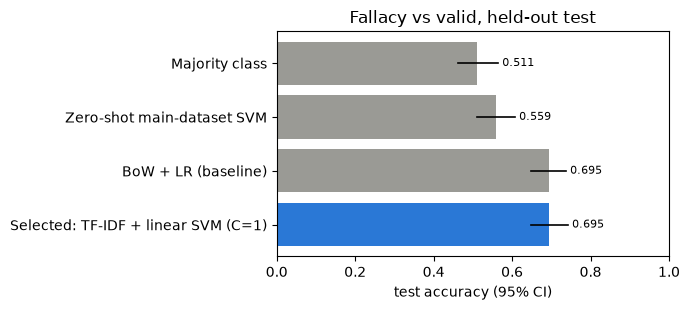

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
tb = test_bin.set_index("model")
ax.barh(tb.index[::-1], tb.accuracy[::-1], color=["#2a78d6" if n.startswith("Selected") else "#9a9a95" for n in tb.index[::-1]])
for i, (n, r) in enumerate(tb[::-1].iterrows()):
    lo, hi = map(float, r.accuracy_95ci.strip("[]").split(","))
    ax.plot([lo, hi], [i, i], c="k", lw=1.2); ax.text(hi + 0.01, i, f"{r.accuracy:.3f}", va="center", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("test accuracy (95% CI)"); ax.set_title("Fallacy vs valid, held-out test")
plt.tight_layout(); plt.savefig(FIGURES / "binary_test_accuracy.png", dpi=150); plt.show()

## 12.6 Errors on test

In [11]:
pd.set_option("display.max_colwidth", 200)
err = te[te.pred != te.is_fallacy].assign(truth=lambda g: g.is_fallacy.map({0: "valid", 1: "fallacy"}))
err.groupby("source").head(4)[["source", "truth", "argument"]]

,source,truth,argument
1,contrastive,fallacy,We should not hire him as a cybersecurity analyst because he posts cringe memes online.
4,contrastive,valid,We should not choose her as lead designer because she has missed every client review this quarter.
7,contrastive,fallacy,He is not qualified to serve as data scientist because he is boring to talk to.
28,contrastive,valid,"It’s alarming to watch rivers dry up, which is why satellite measurements confirming record drought levels matter."
187,cocolofa,fallacy,Azerbaijan has detained a human rights lawyer. But the reason is unclear. Can this type of murky detention be allowed? Who else could be held improperly or mysteriously?
188,cocolofa,valid,I truly hope that Mr. Aslan is released soon; this is a very discouraging news story but not really that surprising. we live in a world where human compassion is severely lacking. It makes me ve...
189,cocolofa,valid,I think this article is jumping to conclusions for too fast. The details of what led to the arrests are really glossed over here. The report clearly hasn't biased where it wants to reach the concl...
191,cocolofa,fallacy,"Most people will agree that while being more responsible for our actions that affect the environment is important, so is the fact that people should be able to provide for their families. Jobs are..."
222,touche,fallacy,What if the group you’re part of is relevant? Is that annoying too? I‘m guilty of doing this when the situation arises but I do it when I actually am part of the group that is being discussed.
225,touche,fallacy,I mean Sir Roger Penrose is one of the leading physicists in the world. Did you even watch the video?


In [12]:
counts = D.groupby(["source", "split"]).is_fallacy.agg(n="count", fallacies="sum").reset_index()
out = {"counts": counts.to_dict("records"), "zero_shot": zs.reset_index().to_dict("records"),
       "zero_shot_pair_rank": zs_pair, "val_grid": vgrid.replace({np.nan: None}).to_dict("records"), "selected": sel["binary"],
       "cross_source_val": cross.to_dict("records"), "test": test_bin.to_dict("records"),
       "test_per_source": per_src.reset_index().to_dict("records"), "test_pair_rank": pair_rank, "test_pair_both": pair_both,
       "n_test_pairs": int(len(tp)), "majority_label": majority,
       "top_fallacy": top(np.argsort(-w)[:12]), "top_valid": top(np.argsort(w)[:12])}
(RESULTS / "binary_summary.json").write_text(json.dumps(out, indent=2, default=str)); print("saved")

saved
